# Lab 01-06 · Techniques of Integration

Companion to chapter [01-06](../../chapters/01-06-techniques-of-integration.md). Handout: [README.md](README.md).

Run the cells in order. Cells marked **🔮 Predict** ask you to write a prediction *before* running.

In [1]:
import math, shutil, subprocess, sys
from pathlib import Path
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.integrate import quad
sys.path.insert(0, str(Path.cwd().parents[3] / "tools"))
try:
    from plotstyle import use_style; use_style()
except ImportError:
    pass

## Part 1 — SymPy as a checking partner

SymPy integrates symbolically. Use it to *check* your hand work, not to replace it. Note what it returns when no elementary antiderivative exists.

In [2]:
x, s, t = sp.symbols("x s t", positive=True)
examples = {
    "substitution  2x/(1+x^2)": 2 * x / (1 + x**2),
    "by parts      x e^x":      x * sp.exp(x),
    "by parts      ln x":       sp.log(x),
    "loop          e^x cos 3x": sp.exp(x) * sp.cos(3 * x),
    "no elementary e^(-x^2)":   sp.exp(-x**2),
}
for name, f in examples.items():
    F = sp.integrate(f, x)
    ok = sp.simplify(sp.diff(F, x) - f) == 0
    print(f"{name:<28} -> {F}   (derivative check: {ok})")
print("\npartial fractions:", sp.apart(10 / ((s + 2) * (s + 5)), s))
print("partial fractions:", sp.apart(1 / (x * (x + 1)**2), x))

substitution  2x/(1+x^2)     -> log(x**2 + 1)   (derivative check: True)
by parts      x e^x          -> (x - 1)*exp(x)   (derivative check: True)
by parts      ln x           -> x*log(x) - x   (derivative check: True)
loop          e^x cos 3x     -> 3*exp(x)*sin(3*x)/10 + exp(x)*cos(3*x)/10   (derivative check: True)
no elementary e^(-x^2)       -> sqrt(pi)*erf(x)/2   (derivative check: True)

partial fractions: -10/(3*(s + 5)) + 10/(3*(s + 2))
partial fractions: -1/(x + 1) - 1/(x + 1)**2 + 1/x


## Part 2 — Fourier coefficients by numerical integration

Compute $b_n = \frac{2}{T}\int_0^T x(t)\sin(n\omega t)\,dt$ for square, triangle and sawtooth waves, then rebuild each wave from 15 harmonics.

**🔮 Predict:** which wave needs the most harmonics to look right, and why?

square    b1..b5 = +1.2732, -0.0000, +0.4244, -0.0000, +0.2546
triangle  b1..b5 = +0.8106, -0.0000, -0.0901, +0.0000, +0.0324
sawtooth  b1..b5 = -0.6366, -0.3183, -0.2122, -0.1592, -0.1273


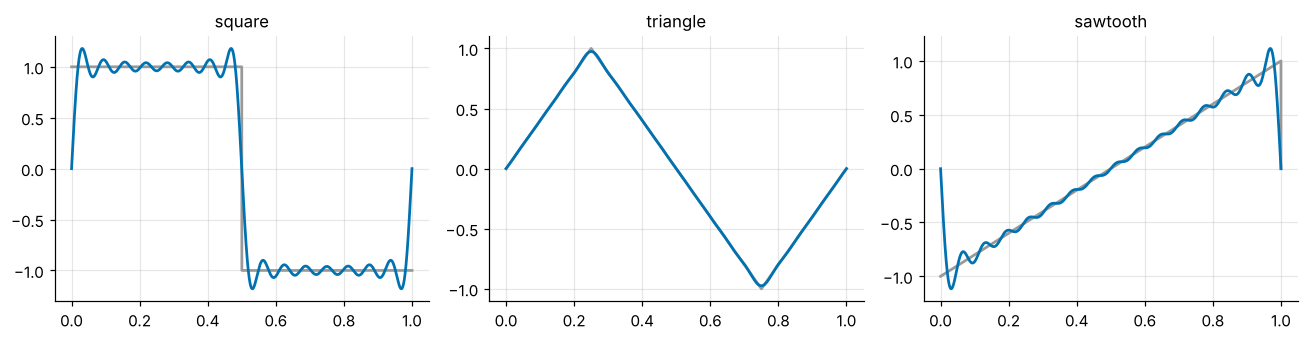

square: 4/pi = 1.2732;  triangle: 8/pi^2 = 0.8106


In [3]:
T = 1.0
tt = np.linspace(0, T, 20001)
waves = {
    "square":   np.where(tt < T / 2, 1.0, -1.0),
    "triangle": np.interp(tt, [0, T/4, 3*T/4, T], [0, 1, -1, 0]),
    "sawtooth": np.where(tt < T, 2 * tt / T - 1, 0.0),
}
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, (name, xw) in zip(axes, waves.items()):
    a0 = np.trapezoid(xw, tt) / T
    recon = np.full_like(tt, a0)
    bs = []
    for n in range(1, 16):
        an = 2 / T * np.trapezoid(xw * np.cos(2 * np.pi * n * tt / T), tt)
        bn = 2 / T * np.trapezoid(xw * np.sin(2 * np.pi * n * tt / T), tt)
        bs.append(bn)
        recon += an * np.cos(2 * np.pi * n * tt / T) + bn * np.sin(2 * np.pi * n * tt / T)
    ax.plot(tt, xw, color="0.6"); ax.plot(tt, recon); ax.set_title(name)
    print(f"{name:<9} b1..b5 = " + ", ".join(f"{b:+.4f}" for b in bs[:5]))
plt.tight_layout(); plt.show()
print(f"square: 4/pi = {4/math.pi:.4f};  triangle: 8/pi^2 = {8/math.pi**2:.4f}")

**The Gibbs overshoot does not go away.** Add more harmonics and measure the peak of the square wave's partial sum.

In [4]:
tt = np.linspace(0, 0.5, 200001)
for N in [11, 51, 201, 1001]:
    sN = sum(4 / (n * np.pi) * np.sin(2 * np.pi * n * tt) for n in range(1, N + 1, 2))
    print(f"harmonics up to {N:>4}: peak = {sN.max():.4f}")
Si_pi = quad(lambda z: math.sin(z) / z if z else 1.0, 0, math.pi)[0]
print(f"limit (2/pi) Si(pi) = {2 / math.pi * Si_pi:.4f}")

harmonics up to   11: peak = 1.1813
harmonics up to   51: peak = 1.1791


harmonics up to  201: peak = 1.1790


harmonics up to 1001: peak = 1.1790
limit (2/pi) Si(pi) = 1.1790


## Part 3 — Numerical quadrature: easy, oscillating and singular integrands

**🔮 Predict:** which of the three integrals below will Simpson's rule with 20 intervals get wrong by the most?

In [5]:
def simpson(f, a, b, n):
    xs = np.linspace(a, b, n + 1); h = (b - a) / n
    y = f(xs)
    return h / 3 * (y[0] + y[-1] + 4 * y[1:-1:2].sum() + 2 * y[2:-1:2].sum())

cases = [
    ("smooth   ∫0^1 e^(-x^2)",       lambda z: np.exp(-z**2),        0, 1),
    ("oscillating ∫0^π sin(40x)^2",  lambda z: np.sin(40 * z)**2,    0, math.pi),
    ("singular ∫ε^1 1/√x (ε=1e-8)",  lambda z: 1 / np.sqrt(z),       1e-8, 1),
]
for name, f, a, b in cases:
    ref = quad(f, a, b, limit=500)[0]
    print(f"{name:<32} Simpson(20) = {simpson(f, a, b, 20):10.6f}   quad = {ref:.6f}")

smooth   ∫0^1 e^(-x^2)           Simpson(20) =   0.746824   quad = 0.746824
oscillating ∫0^π sin(40x)^2      Simpson(20) =   0.000000   quad = 1.570796
singular ∫ε^1 1/√x (ε=1e-8)      Simpson(20) = 168.385206   quad = 2.000000


## Part 4 — ngspice computes Fourier coefficients and noise integrals

`fourier_coeffs.cir` and `noise_bw.cir` are checked by `python tools/run_spice.py 01-06` from the repository root. The cell below runs them directly if ngspice is installed.

In [6]:
if shutil.which("ngspice"):
    for net in ["fourier_coeffs.cir", "noise_bw.cir"]:
        out = subprocess.run(["ngspice", "-b", net], capture_output=True, text=True).stdout
        print(net)
        for l in out.splitlines():
            key = l.split("=")[0].strip()
            if "=" in l and key in ("b1", "b2", "b3", "b5", "vn1", "vn2", "vn3"):
                print("   " + l.strip())
else:
    print("ngspice not found; see SETUP.md. Skipping.")

fourier_coeffs.cir
   b1                  =  1.27324e+00
   b2                  =  -3.81395e-11
   b3                  =  4.24413e-01
   b5                  =  2.54648e-01
noise_bw.cir
   vn1 = 1.61314E-06
   vn2 = 6.4354E-05
   vn3 = 6.43571E-05


## Your turn

1. In Part 2, add a 30% duty-cycle pulse wave. Do even harmonics appear now? Why?
2. In Part 3, rewrite the singular integral with the substitution $x = u^2$ and apply Simpson's rule again.